# 📊 TickerMiner
Notebook de Analisis Exploratorio de Datos (EDA)

## Preliminares

In [5]:
import pandas as pd

from src.modeling import (
    cargar_datos_clean, filtrar_pares_restantes, separar_train_test,
    categorizar_en_cuantiles
    )
from src.transform import encontrar_columnas
from src.eda_utils import (
    mostrar_asimetrias, mostrar_missings, pintar_columna,
    top_correlaciones, pintar_violin_plots, top_correlaciones_objetivo
)

# Cargar fichero de precios
df_clean = cargar_datos_clean()

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 486 entries, 2017-07-17 to 2026-11-02
Columns: 119 entries, EURUSD_intra_weekly to VIX_pct_chg_50d_yeo
dtypes: float64(119)
memory usage: 455.6 KB


In [6]:
# Missings
mostrar_missings(df_clean)

Series([], dtype: float64)

## Analisis de variables

In [7]:
# Descripcion de variables
columnas_clean = df_clean.columns.tolist()
cadena = "SPY_"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)

df_clean[columnas].describe().T

,count,mean,std,min,25%,50%,75%,max
SPY_acceleration_zscore_lag1,486.0,-1.071746e-01,1.131335,-4.661481,-0.733551,-0.131991,0.429090,4.991372
SPY_return_zscore_lag1,486.0,1.189918e-01,1.134469,-7.730660,-0.419176,0.246199,0.782709,3.748365
SPY_return_skew_lag1,486.0,-4.113992e-01,0.648235,-2.992343,-0.990097,-0.223461,0.068536,0.866156
SPY_ret_diff_zscore_lag1,486.0,-2.216269e-02,1.097701,-2.989419,-0.773798,-0.074286,0.596642,4.563750
SPY_accel_diff_zscore_lag1,486.0,2.775478e-02,1.107434,-3.160563,-0.696001,-0.089234,0.643143,5.404862
SPY_vol_ratio_lag1,486.0,9.804157e-01,0.191787,0.456473,0.830314,1.024896,1.131641,1.266611
SPY_std_lag1_log,486.0,-3.860783e+00,0.390146,-4.921625,-4.077332,-3.895495,-3.646206,-2.986866
SPY_vol_directional_lag1_log,486.0,-1.946775e-01,0.384475,-1.877375,-0.415372,-0.219170,0.007319,1.779582
SPY_Volume_zscore_lag1_yeo,486.0,-7.310110e-18,1.001030,-4.880688,-0.594737,-0.026480,0.604813,4.367263


In [8]:
# Asimetrias general
mostrar_asimetrias(df_clean)

VIX_level                           2.768150
EURUSD_return_skew_lag1             1.670963
USDCAD_std_lag1_log                 1.533575
Oil_std_lag1_log                    1.182979
GBPUSD_std_lag1_log                 1.125932
USDJPY_sma15_pct_diff_sma50_lag1    1.099798
Oil_return_skew_lag1                1.069748
STLFSI_delta_50d                    0.909056
VIX_level_skew                      0.879101
AUDUSD_gap_skew_lag1                0.874265
Real_yield_delta_50d                0.775453
AUDUSD_std_lag1_log                 0.711123
EURUSD_open_gap_zscore_yeo          0.675451
Oil_return_zscore_lag1              0.665632
SPY_accel_diff_zscore_lag1          0.659881
USDCAD_vol_directional_lag1_log     0.616177
USDCAD_acceleration_zscore_lag1     0.575852
AUDUSD_sma15_pct_diff_sma50_lag1    0.547552
USDJPY_gap_skew_lag1                0.528087
USDCHF_vol_directional_lag1_log     0.466115
USDCAD_gap_skew_lag1                0.464636
SPY_ret_diff_zscore_lag1            0.453881
EURUSD_std

In [41]:
# Asimetria por grupo
cadena = "_delta_"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)
mostrar_asimetrias(df_clean[columnas])

STLFSI_delta_50d        0.909056
Real_yield_delta_50d    0.775453


Cont


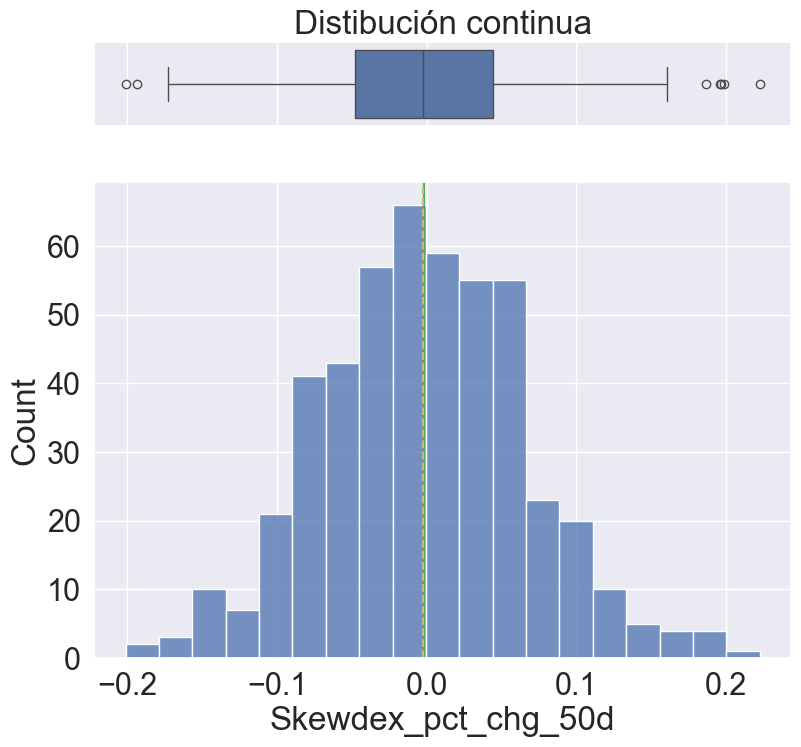

In [9]:
# Visualizar columna
col = 'Skewdex_pct_chg_50d'
pintar_columna(df_clean[col])

## Correlaciones

In [10]:
# Tabla de Correlaciones general
top_correlaciones(df=df_clean, top_n=30)

,Variable A,Variable B,correlation
2079,Oil_accel_diff_zscore_lag1,Oil_ret_diff_zscore_lag1,0.902082
1710,Gold_accel_diff_zscore_lag1,Gold_ret_diff_zscore_lag1,0.900448
350,USDJPY_accel_diff_zscore_lag1,USDJPY_ret_diff_zscore_lag1,0.898565
170,GBPUSD_accel_diff_zscore_lag1,GBPUSD_ret_diff_zscore_lag1,0.894699
2484,SPY_accel_diff_zscore_lag1,SPY_ret_diff_zscore_lag1,0.887609
1274,AUDUSD_accel_diff_zscore_lag1,AUDUSD_ret_diff_zscore_lag1,0.886012
902,USDCHF_accel_diff_zscore_lag1,USDCHF_ret_diff_zscore_lag1,0.879609
594,USDCAD_accel_diff_zscore_lag1,USDCAD_ret_diff_zscore_lag1,0.878693
54,EURUSD_accel_diff_zscore_lag1,EURUSD_ret_diff_zscore_lag1,0.872242
223,GBPUSD_sma15_pct_diff_sma50_lag1,EURUSD_sma15_pct_diff_sma50_lag1,0.864283


In [11]:
# Correlaciones con la variable objetivo continua
simbolo_objetivo = 'EURUSD'
objetivo = f"{simbolo_objetivo}_intra_weekly"

top_correlaciones_objetivo(df=df_clean, target_col=objetivo)

,Variable,Correlación
0,USDCHF_intra_weekly,-0.733096
1,GBPUSD_intra_weekly,0.691733
2,AUDUSD_intra_weekly,0.512561
3,USDJPY_intra_weekly,-0.432457
4,USDCAD_intra_weekly,-0.337270
5,EURUSD_range10_position_lag1,-0.231267
6,AUDUSD_vol_directional_lag1_log,0.221033
7,EURUSD_vol_directional_lag1_log,0.205804
8,USDCHF_range10_position_lag1,0.192897
9,DXY_pct_chg_50d,0.184733


## Analisis de label categorica

In [12]:
# Filtrar pares restantes
df_filtrado = filtrar_pares_restantes(df_clean,simbolo_objetivo)

# Separar datos de entrenamiento y test  
ultima_fecha = df_filtrado.index.max()
df_train, df_live = separar_train_test(df=df_filtrado, fecha=ultima_fecha)

# Se crea la variable categorica a partir del dataset de entrenamiento
# Variable objetivo: se crea variable categorica por cuantiles

objetivo_cat = f"{objetivo}_cat"

df_train, tabla_bins = categorizar_en_cuantiles(
    df_train, 
    columna=objetivo, 
    num_cuantiles=3, 
    quitar_original=True
    )


print(f"\n--- Rangos por Categoría para el ticker {simbolo_objetivo} ---")
print(tabla_bins)


--- Rangos por Categoría para el ticker EURUSD ---
   categoria  lim_inferior  lim_superior
0          1     -3.150490     -0.480573
1          2     -0.480573      0.433932
2          3      0.433932      3.688076


In [13]:
df_train[objetivo_cat].value_counts()

EURUSD_intra_weekly_cat
1    162
3    162
2    161
Name: count, dtype: int64



In [14]:
# Violin plot
# Identificar las variables numéricas excluyendo la variable objetivo
target_col = objetivo_cat
numeric_cols = df_train.select_dtypes(include=["number"]).columns.tolist()

# Asegurar que la columna objetivo no esté en la lista
numeric_cols = [col for col in numeric_cols if col != target_col]


pintar_violin_plots(
    df=df_train,
    numeric_cols=numeric_cols,
    target_col=target_col
)